In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPooling2D
from tensorflow.keras.utils import to_categorical

In [3]:
data = pd.read_csv("cifar-10.csv")

print(data.head())
print("Dataset Shape:", data.shape)

   pixel_0  pixel_1  pixel_2  pixel_3  pixel_4  pixel_5  pixel_6  pixel_7  \
0       59       43       50       68       98      119      139      145   
1      154      126      105      102      125      155      172      180   
2      255      253      253      253      253      253      253      253   
3       28       37       38       42       44       40       40       24   
4      170      168      177      183      181      177      181      184   

   pixel_8  pixel_9  ...  pixel_3063  pixel_3064  pixel_3065  pixel_3066  \
0      149      149  ...        58.0        65.0        59.0        46.0   
1      142      111  ...        42.0        67.0       101.0       122.0   
2      253      253  ...        83.0        80.0        69.0        66.0   
3       32       43  ...        39.0        59.0        42.0        44.0   
4      189      189  ...        88.0        85.0        82.0        83.0   

   pixel_3067  pixel_3068  pixel_3069  pixel_3070  pixel_3071  label  
0        

In [ ]:
# Separate Features and Labels

In [4]:
# Convert all columns to numeric values
data = data.apply(pd.to_numeric, errors='coerce')

# Remove rows where label is missing
data = data.dropna(subset=['label'])

# Fill missing pixel values with 0
data = data.fillna(0)

# Separate features and labels
X = data.drop("label", axis=1).values
y = data["label"].astype(int).values

print("Features Shape:", X.shape)
print("Labels Shape:", y.shape)
print("Classes:", np.unique(y))

Features Shape: (10684, 3072)
Labels Shape: (10684,)
Classes: [0 1 2 3 4 5 6 7 8 9]


In [ ]:
# Normalize Pixel Values

In [5]:
X = X / 255.0

In [54]:
# Reshape Images

In [34]:
# Get original pixel values again
X = data.drop("label", axis=1).values

# Reshape into RGB channels
X = X.reshape(-1, 3, 32, 32)

# Convert into standard image format
X = X.transpose(0, 2, 3, 1)

In [ ]:
# Split Dataset

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (8547, 32, 32, 3)
Testing Data: (2137, 32, 32, 3)


In [ ]:
# Define Class Names

In [37]:
class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

In [ ]:
# Build FNN Model

In [38]:
model = Sequential([
    Flatten(input_shape=(32, 32, 3)),

    Dense(512, activation='relu'),
    Dense(256, activation='relu'),

    Dense(10, activation='softmax')
])

model.summary()

C:\Users\Dell\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)                  │ (None, 3072)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 512)                 │       1,573,376 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 10)                  │           2,570 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,707,274 (6.51 MB)

 Trainable params: 1,707,274 (6.51 MB)

 Non-trainable params: 0 (0.00 B)

In [39]:
# Compile Model

In [40]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

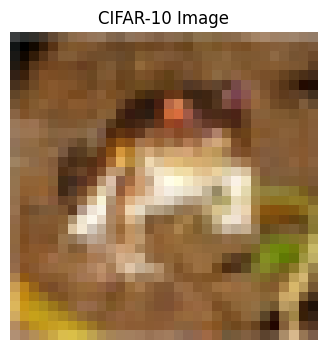

In [41]:
plt.figure(figsize=(4, 4))

plt.imshow(X[0].astype('uint8'))

plt.title("CIFAR-10 Image")
plt.axis('off')

plt.show()

In [43]:
# Model Training

In [44]:
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 9s 47ms/step - accuracy: 0.1743 - loss: 145.6549 - val_accuracy: 0.2000 - val_loss: 19.5522
Epoch 2/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - accuracy: 0.2140 - loss: 10.6619 - val_accuracy: 0.1895 - val_loss: 10.5164
Epoch 3/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - accuracy: 0.2345 - loss: 6.4546 - val_accuracy: 0.1754 - val_loss: 7.6341
Epoch 4/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step - accuracy: 0.2447 - loss: 4.9863 - val_accuracy: 0.2047 - val_loss: 6.4679
Epoch 5/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.2738 - loss: 3.6455 - val_accuracy: 0.2421 - val_loss: 3.5348
Epoch 6/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step - accuracy: 0.2726 - loss: 3.0104 - val_accuracy: 0.2480 - val_loss: 3.0871
Epoch 7/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.2937 - loss: 2.5481 - val_accuracy: 0.2795 - val_loss: 2.7229
Epoch 8/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step - accuracy: 0.3189 - loss: 2.1858 - val

In [45]:
# Training and Testing Accuracy

In [46]:
train_loss, train_acc = model.evaluate(X_train, y_train)
test_loss, test_acc = model.evaluate(X_test, y_test)

print("Training Accuracy:", train_acc * 100, "%")
print("Testing Accuracy:", test_acc * 100, "%")

268/268 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.3201 - loss: 2.0303
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.2723 - loss: 2.2536
Training Accuracy: 32.011231780052185 %
Testing Accuracy: 27.23444104194641 %


In [47]:
# Display Predicted Class Labels

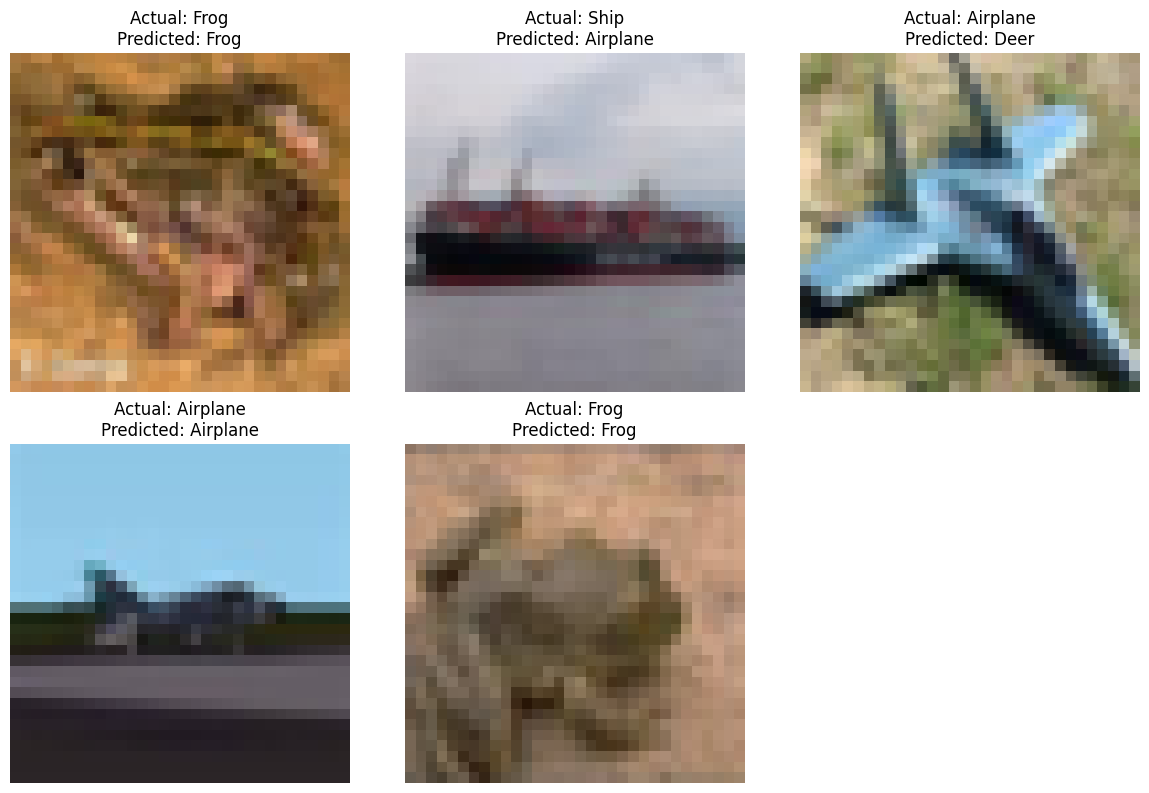

In [53]:
plt.figure(figsize=(12, 8))

for i in range(5):

    plt.subplot(2, 3, i+1)

    # Normalize image only for displaying
    image = X_test[i]

    if image.max() > 1:
        image = image / 255.0

    plt.imshow(image)

    actual = class_names[y_test[i]]
    predicted = class_names[predicted_labels[i]]

    plt.title("Actual: " + actual + "\nPredicted: " + predicted)

    plt.axis('off')

plt.tight_layout()
plt.show()


Here are **25 important code-based viva questions with answers** for Practical 14 – FNN using CIFAR-10.

## FNN – CIFAR-10: 25 Viva Questions

**1. What is CIFAR-10?**  
CIFAR-10 is an image dataset containing 10 different object categories.

**2. What are the 10 classes in CIFAR-10?**  
Airplane, Automobile, Bird, Cat, Deer, Dog, Frog, Horse, Ship and Truck.

**3. Which function is used to load CIFAR-10?**  
`cifar10.load_data()` – It loads the CIFAR-10 dataset.

**4. How many training images are present in CIFAR-10?**  
50,000 images.

**5. How many testing images are present?**  
10,000 images.

**6. What is the size of each CIFAR-10 image?**  
32 × 32 pixels with 3 color channels (RGB).

**7. What does RGB represent?**  
Red, Green and Blue color channels.

**8. What is the purpose of `X_train`?**  
It stores the training images.

**9. What does `y_train` contain?**  
It contains the actual class labels of training images.

**10. Why do we divide image values by 255?**  
To normalize pixel values from 0–255 to 0–1.

**11. Why do we use `Flatten()` in FNN?**  
It converts a 3D image (32 × 32 × 3) into a 1D array of 3072 values.

**12. What is the purpose of `Sequential()`?**  
It creates a neural network by adding layers sequentially.

**13. What is a Dense layer?**  
A fully connected layer where every neuron connects to all neurons in the previous layer.

**14. What does `Dense(128, activation='relu')` mean?**  
It creates a hidden layer with 128 neurons using ReLU activation.

**15. What is ReLU activation?**  
It converts negative values into zero and keeps positive values unchanged.

**16. Why do we use `Dense(10, activation='softmax')`?**  
Because CIFAR-10 has 10 output classes. Softmax calculates the probability of each class.

**17. What is the purpose of `model.compile()`?**  
It configures the model with an optimizer, loss function and evaluation metric.

**18. Which optimizer is used in this practical?**  
Adam optimizer. It updates model weights to reduce errors.

**19. Which loss function is used for CIFAR-10 classification?**  
Sparse categorical crossentropy.

**20. What is the purpose of `model.fit()`?**  
It trains the model using training images and their labels.

**21. What is an epoch?**  
One complete pass through the entire training dataset.

**22. What is the purpose of `model.evaluate(X_test, y_test)`?**  
It evaluates the model's performance on testing images.

**23. What does `model.predict()` do?**  
It predicts the output probabilities for test images.

**24. Why do we use `np.argmax(prediction, axis=1)`?**  
It returns the class index having the highest predicted probability for each image.

**25. Why do we use `class_names[predicted_label]`?**  
To convert the predicted numerical class into its actual category name, such as Cat, Dog or Airplane.

---

### Important code statements to remember

| Code | Purpose |
|---|---|
| `cifar10.load_data()` | Loads CIFAR-10 dataset |
| `X_train / 255.0` | Normalizes images |
| `Flatten()` | Converts image into 3072 values |
| `Dense(128, activation='relu')` | Creates hidden layer |
| `Dense(10, activation='softmax')` | Creates 10 output classes |
| `model.compile()` | Configures model |
| `model.fit()` | Trains model |
| `model.evaluate()` | Evaluates model |
| `model.predict()` | Predicts image classes |
| `np.argmax()` | Finds predicted class index |

**Important viva point:** CIFAR-10 contains colored images (RGB), whereas MNIST contains grayscale handwritten digit images. CIFAR-10 is generally more challenging to classify using an FNN because flattening removes the spatial arrangement of image pixels.